In [1]:
# ==========================================================
#                   Universidad Franz Tamayo
# ----------------------------------------------------------
#                        MINERIA DE DATOS
# ----------------------------------------------------------
#  Tarea H4.1: K-Means Clustering aplicado al proyecto
#  Segmentación de usuarios de MovieLens (ml-latest-small)
# ==========================================================

**Grupo:** _____

**Integrantes:**
- _____
- _____

# Segmentación de Usuarios de MovieLens mediante K-Means
### Universidad Franz Tamayo — Minería de Datos, 2026

---

## Objetivos

1. Diferenciar el aprendizaje supervisado, aplicado en los hitos anteriores mediante regresión logística y árboles de decisión, del aprendizaje no supervisado.
2. Describir el funcionamiento del algoritmo K-Means.
3. Implementar K-Means en Python con scikit-learn sobre los datos del proyecto.
4. Interpretar y caracterizar los grupos de usuarios obtenidos.
5. Evaluar la calidad del agrupamiento mediante métricas internas.

---

## Estructura del documento

| Sección | Contenido |
|---|---|
| 1 | Marco teórico |
| 2 | Actividad 1: reflexión conceptual |
| 3 | Exploración del conjunto de datos |
| 4 | Preprocesamiento |
| 5 | Implementación de K-Means |
| 6 | Actividad 2: interpretación de los clusters |
| 7 | Evaluación y métricas |
| 8 | Conclusiones |

---

**Conjunto de datos.** Se utiliza MovieLens `ml-latest-small` (GroupLens Research, Universidad de Minnesota), que contiene 100,836 calificaciones y 3,683 etiquetas asignadas por 610 usuarios a 9,742 películas. En los hitos anteriores la unidad de análisis fue la calificación individual, con el objetivo de predecir si era alta o baja. En el presente trabajo la unidad de análisis es el usuario: se construye un perfil de comportamiento para cada uno y se identifican grupos de usuarios similares sin recurrir a una variable objetivo.

---
# Parte 1: Marco teórico

---

## Aprendizaje supervisado y no supervisado en el proyecto

### Aprendizaje supervisado (hito 3)
- El modelo aprende a partir de datos etiquetados.
- En el proyecto se predijo si una calificación es alta (≥ 4.0) o baja a partir de `genre_count`, `user_mean_rating`, `user_rating_count` y `year`.
- Se emplearon regresión logística (exactitud 0.655, AUC 0.722) y árbol de decisión (exactitud 0.658, AUC 0.726).

### Aprendizaje no supervisado (hito 4)
- El modelo identifica patrones sin disponer de una variable objetivo.
- En el proyecto se agrupa a los 610 usuarios según su forma de calificar (volumen de actividad, nivel de las calificaciones, consistencia y tipo de películas), sin conocer de antemano el número de grupos existentes.
- Algoritmo empleado: K-Means.

```
SUPERVISADO (hito 3)              NO SUPERVISADO (hito 4)
────────────────────              ───────────────────────
Ratings + etiqueta alto/bajo      Perfil de cada usuario
          │                                │
   Regresión / Árbol                    K-Means
          │                                │
 ¿El rating será alto?            ¿Qué tipos de usuario existen?
```

## Concepto de clustering

El clustering consiste en dividir un conjunto de datos en grupos de manera que:
- los elementos de un mismo grupo sean lo más similares posible entre sí, y
- los elementos de grupos distintos sean lo más diferentes posible.

### Aplicaciones en un sistema de recomendación

| Aplicación | Ejemplo en MovieLens |
|---|---|
| Recomendación por segmento | Sugerir películas antiguas a usuarios que consumen principalmente ese catálogo |
| Arranque en frío | Asignar a un usuario nuevo el segmento más cercano a su comportamiento inicial |
| Corrección de sesgo | Normalizar las calificaciones de usuarios con tendencia a calificar alto o bajo |
| Retención | Identificar usuarios que dejaron de calificar hace tiempo |

---

## Funcionamiento del algoritmo K-Means

1. **Inicialización.** Se eligen K centroides iniciales. scikit-learn emplea por defecto el método *k-means++*, que distribuye los centroides iniciales de forma separada.
2. **Asignación.** Cada usuario se asigna al centroide más cercano según la distancia euclidiana.
3. **Actualización.** Cada centroide se recalcula como el promedio de los usuarios asignados a su grupo.
4. **Convergencia.** Los pasos 2 y 3 se repiten hasta que las asignaciones no cambian o se alcanza el número máximo de iteraciones.

## Fundamento matemático

### Distancia euclidiana
Para dos usuarios $p$ y $q$ descritos por $n$ variables:

$$d(p, q) = \sqrt{\sum_{i=1}^{n}(p_i - q_i)^2}$$

Ejemplo en dos dimensiones (número de calificaciones y calificación promedio):

$$d = \sqrt{(NumRatings_1 - NumRatings_2)^2 + (MeanRating_1 - MeanRating_2)^2}$$

Sin escalamiento, `NumRatings` (entre 20 y más de 2,000) dominaría la distancia frente a `MeanRating` (entre 0.5 y 5). Por esta razón las variables se escalan en la Parte 3.

---

### Función objetivo: WCSS
K-Means minimiza la suma de cuadrados intra-cluster (*Within-Cluster Sum of Squares*):

$$WCSS = \sum_{k=1}^{K} \sum_{x_i \in C_k} \|x_i - \mu_k\|^2$$

donde $K$ es el número de clusters, $C_k$ el conjunto de usuarios del cluster $k$ y $\mu_k$ su centroide.

Un WCSS menor indica clusters más compactos. Sin embargo, el WCSS disminuye siempre al aumentar K, por lo que no es suficiente por sí solo para elegir el número de clusters.

---

## Ventajas y limitaciones de K-Means

| Ventajas | Limitaciones |
|---|---|
| Simplicidad conceptual | Requiere definir K de antemano |
| Escalabilidad | Sensibilidad a valores atípicos (en MovieLens existen usuarios con miles de calificaciones) |
| Bajo costo computacional | Supone clusters de forma aproximadamente esférica y tamaño similar |
| Centroides interpretables | El resultado depende de la inicialización |

---

## Comparación con otros algoritmos

| Característica | K-Means | DBSCAN | Jerárquico |
|---|---|---|---|
| Requiere definir K | Sí | No | No |
| Forma de los clusters | Esférica | Arbitraria | Arbitraria |
| Tratamiento de atípicos | No | Sí | Parcial |
| Escalabilidad | Alta | Media | Baja |
| Interpretabilidad | Alta | Media | Alta (dendrograma) |

---
# Actividad 1: Reflexión conceptual

---

**1.** Si se tuviera que agrupar manualmente a los 610 usuarios de MovieLens, ¿qué criterios se utilizarían?

**Respuesta.** Se considerarían cuatro criterios: el volumen de actividad (número de películas calificadas, que distingue a usuarios ocasionales de usuarios intensivos), la tendencia al calificar (usuarios que asignan habitualmente 4 o 5 frente a usuarios con promedios bajos), la dispersión de las calificaciones (uso de toda la escala o concentración en pocos valores) y el tipo de películas consumidas (año de estreno y variedad de géneros).

---

**2.** A partir de las variables disponibles (`rating`, `timestamp`, `genres`, año en `title`, `tag`), ¿cuántos grupos de usuarios se espera encontrar y por qué?

**Respuesta.** Como hipótesis inicial se esperan entre tres y cinco grupos: (a) usuarios ocasionales con pocas calificaciones, (b) usuarios muy activos con un historial extenso, (c) usuarios que califican alto, (d) usuarios que califican bajo y, posiblemente, (e) usuarios orientados a películas antiguas. El número de grupos se determina posteriormente mediante el método del codo y el coeficiente de silueta, no por intuición.

---

**3.** ¿Qué variables resultan más útiles para agrupar usuarios y por qué?

**Respuesta.** Las variables de comportamiento agregadas por usuario: número de calificaciones, calificación promedio, desviación estándar de las calificaciones, número de etiquetas, días de actividad, días transcurridos desde la última calificación, año promedio de estreno de las películas calificadas y diversidad de géneros. Se excluyen `userId` y `movieId` por ser identificadores sin significado numérico, así como `imdbId` y `tmdbId` de `links.csv`, que solo permiten enlazar con otras bases de datos. El conjunto no incluye información demográfica, por lo que la segmentación se basa exclusivamente en el comportamiento.

---

**4.** ¿Por qué es relevante para una plataforma de recomendación conocer los distintos tipos de usuarios?

**Respuesta.** En primer lugar, una misma calificación no tiene el mismo significado para un usuario que califica alto de forma habitual que para uno más estricto. En segundo lugar, la estrategia de recomendación para un usuario con pocos datos difiere de la aplicable a un usuario con cientos de calificaciones. Finalmente, la segmentación permite personalizar recomendaciones y campañas de reactivación. Esto es coherente con el hito 3, en el que `user_mean_rating` resultó la variable más importante del árbol de decisión.

---
# Parte 2: Implementación en Python

---

## Paso 0: Importación de librerías

| Librería | Uso |
|---|---|
| `pandas` | Manipulación de datos tabulares |
| `numpy` | Operaciones numéricas |
| `matplotlib` / `seaborn` | Visualización |
| `sklearn.cluster.KMeans` | Algoritmo K-Means |
| `sklearn.preprocessing.StandardScaler` | Estandarización de variables |
| `sklearn.decomposition.PCA` | Proyección a dos dimensiones, empleada únicamente para visualizar |
| `sklearn.metrics` | Coeficiente de silueta, índice de Davies-Bouldin e índice de Calinski-Harabasz |

In [2]:
# Si hace falta instalar dependencias, descomenta la siguiente línea:
# %pip install pandas numpy matplotlib seaborn scikit-learn

# ── Librerías estándar ───────────────────────────────────────
import io                      # leer el zip descargado en memoria
import urllib.request          # descargar el dataset si no está en disco
import warnings                # silenciar advertencias no críticas
import zipfile                 # descomprimir ml-latest-small.zip
from pathlib import Path       # manejo de rutas independiente del sistema operativo

# ── Librerías de manipulación de datos ──────────────────────
import numpy as np             # operaciones numéricas (log1p, arreglos)
import pandas as pd            # DataFrames

# ── Librerías de visualización ───────────────────────────────
import matplotlib.pyplot as plt  # gráficos base
import seaborn as sns            # gráficos estadísticos (heatmaps)
from IPython.display import display  # mostrar DataFrames dentro de un bloque

# ── Librerías de Machine Learning ────────────────────────────
from sklearn.cluster import KMeans                    # algoritmo de clustering
from sklearn.decomposition import PCA                 # reducir a 2D para graficar
from sklearn.metrics import (silhouette_score,        # cohesión vs. separación
                             davies_bouldin_score,    # similitud entre clusters (menor = mejor)
                             calinski_harabasz_score) # dispersión entre / dentro (mayor = mejor)
from sklearn.preprocessing import StandardScaler      # media 0, desviación 1

# ── Configuración de estilo y rutas ──────────────────────────
warnings.filterwarnings('ignore')                     # salidas más limpias
plt.style.use('seaborn-v0_8-whitegrid')               # estilo de gráficos
plt.rcParams['figure.figsize'] = (10, 6)              # tamaño por defecto
plt.rcParams['font.size'] = 12                        # tamaño de letra por defecto

RANDOM_STATE = 777                                    # semilla para reproducibilidad
DATA_DIR = Path('./ml-latest-small')                  # misma carpeta de datos que el EDA del hito 2
OUTPUT_DIR = Path('./output_kmeans')                  # carpeta de salida de este hito
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)         # crearla si no existe

print("Librerías cargadas correctamente")
print(f"   pandas  {pd.__version__}")
print(f"   numpy   {np.__version__}")
print('Datos :', DATA_DIR.resolve())
print('Salida:', OUTPUT_DIR.resolve())

Librerías cargadas correctamente
   pandas  3.1.1
   numpy   2.5.4
Datos : /home/ruper/Documentos/mineria_datos/ml-latest-small
Salida: /home/ruper/Documentos/mineria_datos/output_kmeans


In [3]:
def save_plot(filename):
    """Guarda la figura actual en OUTPUT_DIR y la muestra (igual que en el hito 2)."""
    plt.tight_layout()                                          # evitar solapamientos
    plt.savefig(OUTPUT_DIR / filename, dpi=150, bbox_inches='tight')  # guardar en disco
    plt.show()                                                  # mostrar en el notebook
    plt.close()                                                 # liberar memoria

---
## Paso 1: Carga e inspección inicial de los datos

Se emplean los mismos archivos del análisis exploratorio del hito 2. Si la carpeta `ml-latest-small/` no existe, los datos se descargan desde el sitio oficial de GroupLens.

In [4]:
# ── Descargar el dataset si no está en disco ─────────────────
URL = 'https://files.grouplens.org/datasets/movielens/ml-latest-small.zip'  # fuente oficial

if not (DATA_DIR / 'ratings.csv').exists():                    # solo descargar si falta
    print('Descargando', URL)
    with urllib.request.urlopen(URL, timeout=120) as resp:     # descargar el zip
        zipfile.ZipFile(io.BytesIO(resp.read())).extractall('.')  # descomprime en ./ml-latest-small/

# ── Cargar los archivos ──────────────────────────────────────
movies = pd.read_csv(DATA_DIR / 'movies.csv')                  # movieId, title, genres
ratings = pd.read_csv(DATA_DIR / 'ratings.csv')                # userId, movieId, rating, timestamp
tags = pd.read_csv(DATA_DIR / 'tags.csv')                      # userId, movieId, tag, timestamp

print("Dataset cargado exitosamente")
for nombre, frame in {'movies': movies, 'ratings': ratings, 'tags': tags}.items():
    print(f"   {nombre:<8}: {frame.shape[0]:>7,} filas | {frame.shape[1]} columnas")  # dimensiones
print()
print(f"   Usuarios únicos con ratings: {ratings['userId'].nunique():,}")  # unidad de análisis de este hito
print()
print("Primeras 5 filas de ratings:")
ratings.head()

Dataset cargado exitosamente
   movies  :   9,742 filas | 3 columnas
   ratings : 100,836 filas | 4 columnas
   tags    :   3,683 filas | 4 columnas

   Usuarios únicos con ratings: 610

Primeras 5 filas de ratings:


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [5]:
# ── Información general de los DataFrames ───────────────────
print("ratings:")
ratings.info()          # tipos de datos y memoria
print()
print("movies:")
movies.info()

ratings:
<class 'pandas.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB

movies:
<class 'pandas.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   movieId  9742 non-null   int64
 1   title    9742 non-null   str  
 2   genres   9742 non-null   str  
dtypes: int64(1), str(2)
memory usage: 228.5 KB


In [6]:
# ── Estadísticas descriptivas del rating ─────────────────────
print("Estadísticas descriptivas de ratings:")
ratings[['rating']].describe().round(2)

Estadísticas descriptivas de ratings:


,rating
count,100836.00
mean,3.50
std,1.04
min,0.50
25%,3.00
50%,3.50
75%,4.00
max,5.00


In [7]:
# ── Valores nulos ────────────────────────────────────────────
for nombre, frame in {'movies': movies, 'ratings': ratings, 'tags': tags}.items():
    nulos = frame.isnull().sum()                     # nulos por columna
    nulos = nulos[nulos > 0]                         # solo columnas con nulos
    if nulos.empty:
        print(f"{nombre}: no hay valores nulos")
    else:
        print(f"{nombre}: columnas con nulos")
        print((nulos / len(frame) * 100).round(2).rename('porcentaje (%)'))

movies: no hay valores nulos
ratings: no hay valores nulos
tags: no hay valores nulos


---
## Paso 2: Ingeniería de variables (perfil por usuario)

K-Means requiere una fila por cada elemento a agrupar. Dado que se agrupan usuarios, las 100,836 filas de `ratings` (una por calificación) se transforman en 610 filas (una por usuario) con las siguientes variables:

| Variable | Cálculo | Interpretación |
|---|---|---|
| `NumRatings` | Número de calificaciones del usuario | Nivel de actividad |
| `MeanRating` | Promedio de sus calificaciones | Tendencia a calificar alto o bajo |
| `StdRating` | Desviación estándar de sus calificaciones | Amplitud de uso de la escala |
| `NumTags` | Número de etiquetas registradas | Participación adicional a la calificación |
| `ActiveDays` | Días entre la primera y la última calificación | Antigüedad y continuidad |
| `RecencyDays` | Días entre su última calificación y la última del conjunto | Actualidad de la actividad |
| `MeanMovieYear` | Año de estreno promedio de las películas calificadas | Orientación a películas antiguas o recientes |
| `GenreDiversity` | Número de géneros distintos calificados | Variedad de preferencias |

`RecencyDays` cumple la función de `Recency` en el ejercicio de iFood, y `NumRatings` la de `TotalPurchases`.

In [8]:
# ── Preparar columnas auxiliares ─────────────────────────────
ratings['datetime'] = pd.to_datetime(ratings['timestamp'], unit='s')   # segundos Unix → fecha
movies['year'] = pd.to_numeric(                                         # año de estreno desde el título
    movies['title'].str.extract(r'\((\d{4})\)\s*$')[0], errors='coerce')  # "Toy Story (1995)" → 1995
fecha_ref = ratings['datetime'].max()                                   # fecha del último rating del dataset

# ── Unir ratings con información de la película ──────────────
r = ratings.merge(movies[['movieId', 'year', 'genres']], on='movieId', how='left')  # año y géneros por rating

# ── Agregar por usuario ──────────────────────────────────────
users = r.groupby('userId').agg(
    NumRatings=('rating', 'size'),                       # cuántas calificaciones
    MeanRating=('rating', 'mean'),                       # promedio
    StdRating=('rating', 'std'),                         # dispersión
    FirstDate=('datetime', 'min'),                       # primera actividad
    LastDate=('datetime', 'max'),                        # última actividad
    MeanMovieYear=('year', 'mean'),                      # año promedio de las películas vistas
)
users['ActiveDays'] = (users['LastDate'] - users['FirstDate']).dt.days  # antigüedad en días
users['RecencyDays'] = (fecha_ref - users['LastDate']).dt.days          # días sin calificar

# Cantidad de géneros distintos calificados por usuario
generos = r[['userId', 'genres']].assign(genre=r['genres'].str.split('|')).explode('genre')  # un género por fila
generos = generos[generos['genre'] != '(no genres listed)']              # quitar películas sin género
users['GenreDiversity'] = generos.groupby('userId')['genre'].nunique()   # géneros distintos

# Cantidad de tags por usuario (0 si nunca escribió uno)
users['NumTags'] = tags.groupby('userId').size().reindex(users.index, fill_value=0)

users = users.drop(columns=['FirstDate', 'LastDate'])                   # ya no se necesitan
users = users.reset_index()                                              # userId como columna

print("Features creados:")
for col in ['NumRatings', 'MeanRating', 'NumTags', 'ActiveDays', 'RecencyDays', 'MeanMovieYear']:
    print(f"   {col:<14} → min: {users[col].min():.1f}, max: {users[col].max():.1f}")
print(f"\n   Filas (usuarios): {len(users):,}")

users.head()

Features creados:
   NumRatings     → min: 20.0, max: 2698.0
   MeanRating     → min: 1.3, max: 5.0
   NumTags        → min: 0.0, max: 1507.0
   ActiveDays     → min: 0.0, max: 6557.0
   RecencyDays    → min: 0.0, max: 8213.0
   MeanMovieYear  → min: 1964.4, max: 2012.9

   Filas (usuarios): 610


,userId,NumRatings,MeanRating,StdRating,MeanMovieYear,ActiveDays,RecencyDays,GenreDiversity,NumTags
0,1,232,4.366379,0.800048,1983.982759,8,6621,17,0
1,2,29,3.948276,0.805615,2008.448276,0,1065,14,9
2,3,39,2.435897,2.090642,1983.589744,0,2677,15,0
3,4,216,3.555556,1.314204,1988.023148,723,6136,19,0
4,5,44,3.636364,0.990441,1991.022727,0,7990,17,0


---
## Paso 3: Análisis exploratorio

Antes del agrupamiento se examinan las distribuciones, los valores atípicos y las relaciones entre las variables del perfil de usuario.

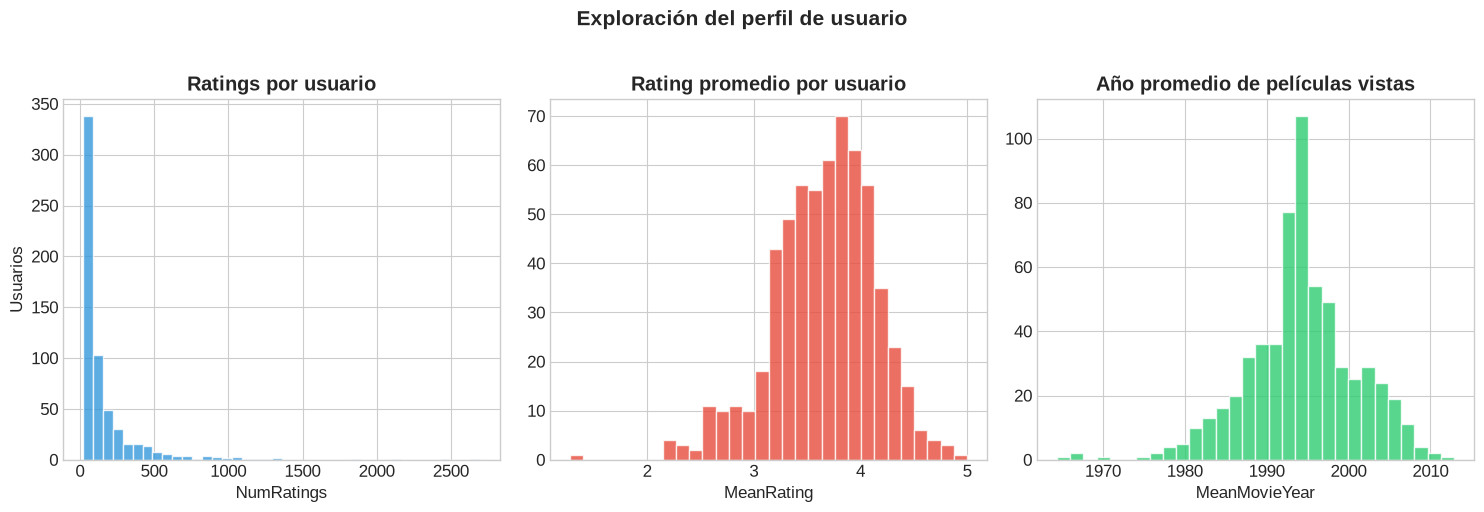

Asimetría (skew) de NumRatings: 4.64
Asimetría (skew) de NumTags   : 18.43


In [9]:
# ── Histogramas de las variables principales ─────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5))                       # 3 gráficos en una fila

axes[0].hist(users['NumRatings'], bins=40, color='#3498db', edgecolor='white', alpha=0.8)
axes[0].set_title('Ratings por usuario', fontweight='bold')
axes[0].set_xlabel('NumRatings')
axes[0].set_ylabel('Usuarios')

axes[1].hist(users['MeanRating'], bins=30, color='#e74c3c', edgecolor='white', alpha=0.8)
axes[1].set_title('Rating promedio por usuario', fontweight='bold')
axes[1].set_xlabel('MeanRating')

axes[2].hist(users['MeanMovieYear'], bins=30, color='#2ecc71', edgecolor='white', alpha=0.8)
axes[2].set_title('Año promedio de películas vistas', fontweight='bold')
axes[2].set_xlabel('MeanMovieYear')

plt.suptitle('Exploración del perfil de usuario', fontsize=15, fontweight='bold', y=1.02)
save_plot('01_histogramas.png')

print(f"Asimetría (skew) de NumRatings: {users['NumRatings'].skew():.2f}")   # >1 = cola larga a la derecha
print(f"Asimetría (skew) de NumTags   : {users['NumTags'].skew():.2f}")

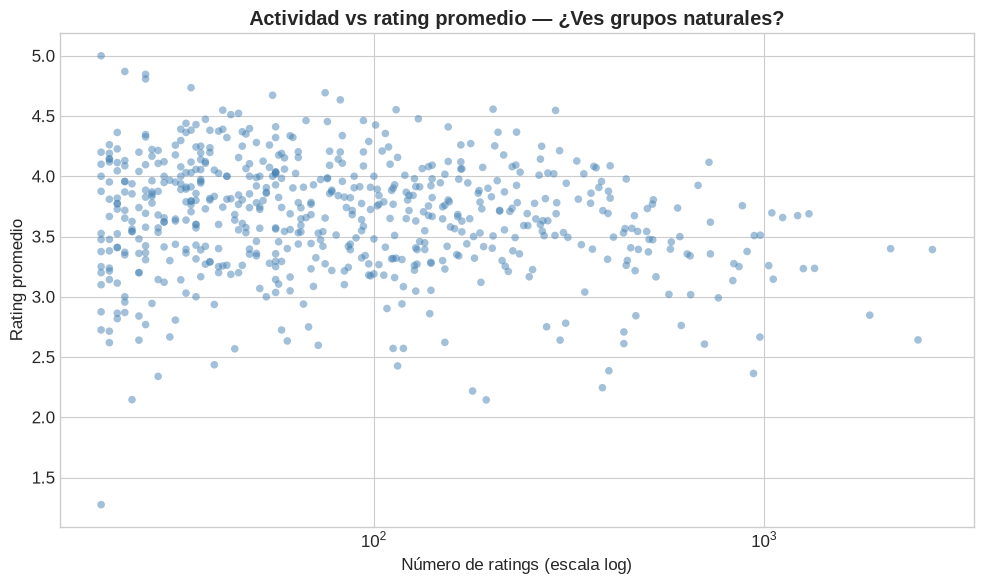

In [10]:
# ── Scatter: NumRatings vs MeanRating ────────────────────────
plt.figure(figsize=(10, 6))
plt.scatter(users['NumRatings'], users['MeanRating'], alpha=0.5, c='steelblue', edgecolors='none', s=30)
plt.xscale('log')                                       # escala log porque NumRatings tiene cola muy larga
plt.title('Actividad vs rating promedio — ¿Ves grupos naturales?', fontweight='bold')
plt.xlabel('Número de ratings (escala log)')
plt.ylabel('Rating promedio')
save_plot('02_scatter_actividad_rating.png')

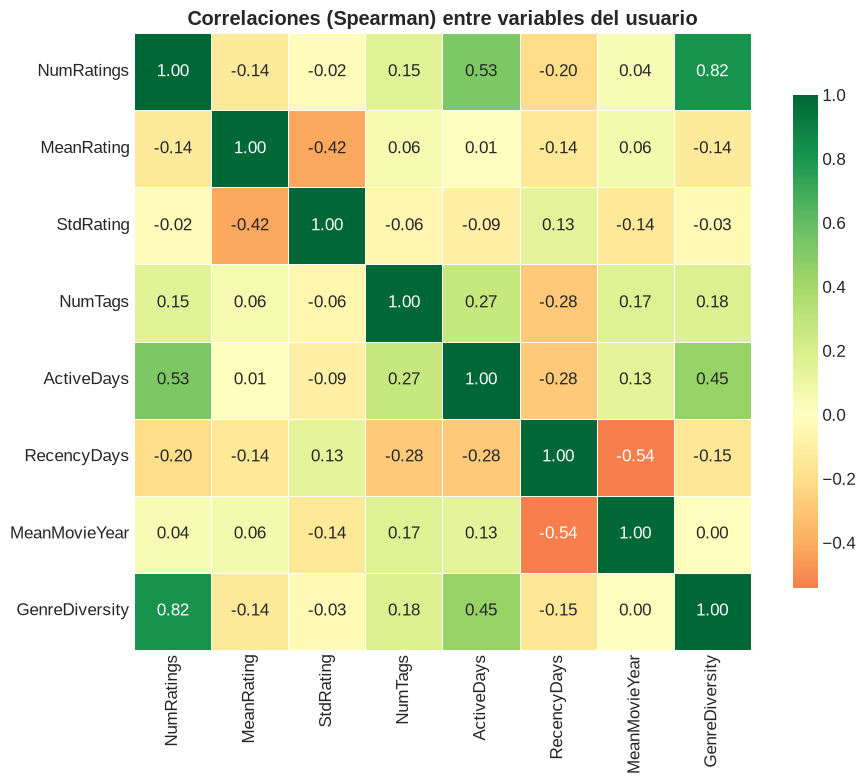

Pares con |r| ≥ 0.7:
NumRatings  GenreDiversity    0.82


In [11]:
# ── Heatmap de correlaciones ─────────────────────────────────
features = ['NumRatings', 'MeanRating', 'StdRating', 'NumTags',
            'ActiveDays', 'RecencyDays', 'MeanMovieYear', 'GenreDiversity']  # variables del perfil

plt.figure(figsize=(10, 8))
corr_matrix = users[features].corr(method='spearman')   # Spearman: robusto a la asimetría y a outliers
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdYlGn', center=0,
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Correlaciones (Spearman) entre variables del usuario', fontweight='bold')
save_plot('03_correlaciones.png')

# Pares con correlación fuerte (|r| ≥ 0.7): aportan información redundante a la distancia
pares = corr_matrix.where(np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1)).stack()  # triángulo superior
print("Pares con |r| ≥ 0.7:")
fuertes = pares[pares.abs() >= 0.7].round(2)
print(fuertes.to_string() if not fuertes.empty else "   ninguno")

---
# Parte 3: Preprocesamiento

---

## Justificación

K-Means se basa en distancias. `NumRatings` alcanza valores de miles, `ActiveDays` abarca miles de días y `MeanRating` varía entre 0.5 y 5. Sin un escalamiento previo, las variables de mayor magnitud determinarían el agrupamiento.

### Transformaciones aplicadas
1. **Transformación logarítmica** $\log(1 + x)$ sobre `NumRatings`, `NumTags` y `ActiveDays`. Estas variables presentan una fuerte asimetría positiva (coeficientes de asimetría de 4.64 y 18.43 para `NumRatings` y `NumTags`). Dado que K-Means es sensible a valores atípicos, sin esta transformación unos pocos usuarios extremos podrían formar un cluster propio o desplazar los centroides.
2. **Estandarización** con `StandardScaler`, que lleva cada variable a media 0 y desviación estándar 1:

$$z = \frac{x - \mu}{\sigma}$$

### Variables seleccionadas

| Variable | Justificación |
|---|---|
| `NumRatings` (log) | Nivel de actividad |
| `MeanRating` | Tendencia al calificar |
| `StdRating` | Uso de la escala de calificación |
| `NumTags` (log) | Participación mediante etiquetas |
| `ActiveDays` (log) | Antigüedad del usuario |
| `RecencyDays` | Actualidad de la actividad |
| `MeanMovieYear` | Orientación a películas antiguas o recientes |
| `GenreDiversity` | Variedad de preferencias |

In [12]:
# ── Selección de features y eliminación de nulos ─────────────
df_cluster = users[['userId'] + features].dropna().copy()   # StdRating o MeanMovieYear podrían ser NaN
print(f"Datos para clustering: {df_cluster.shape[0]:,} usuarios")
print(f"   Filas eliminadas por nulos: {len(users) - len(df_cluster)}")

# ── Transformación logarítmica de variables muy asimétricas ──
log_cols = ['NumRatings', 'NumTags', 'ActiveDays']           # colas largas detectadas en la exploración
X = df_cluster[features].copy()                              # copia para no alterar los valores originales
X[log_cols] = np.log1p(X[log_cols])                          # log(1+x) admite ceros (NumTags = 0)

X.describe().round(2)

Datos para clustering: 610 usuarios
   Filas eliminadas por nulos: 0


,NumRatings,MeanRating,StdRating,NumTags,ActiveDays,RecencyDays,MeanMovieYear,GenreDiversity
count,610.00,610.00,610.00,610.00,610.00,610.00,610.00,610.00
mean,4.47,3.66,0.93,0.21,1.80,4191.22,1994.21,16.40
std,1.05,0.48,0.27,0.81,2.64,2834.49,6.69,2.04
min,3.04,1.27,0.00,0.00,0.00,0.00,1964.36,8.00
25%,3.58,3.36,0.74,0.00,0.00,1335.75,1990.56,15.00
50%,4.27,3.69,0.90,0.00,0.00,4120.50,1993.98,17.00
75%,5.13,4.00,1.08,0.00,3.66,6817.00,1997.74,18.00
max,7.90,5.00,2.09,7.32,8.79,8213.00,2012.89,19.00


In [13]:
# ── Aplicar StandardScaler ────────────────────────────────────
scaler = StandardScaler()                                    # media 0, desviación 1
X_scaled = scaler.fit_transform(X)                           # ajustar y transformar
X_scaled_df = pd.DataFrame(X_scaled, columns=features)       # a DataFrame para inspeccionar

cols_demo = ['NumRatings', 'MeanRating', 'ActiveDays']       # columnas para comparar
print("ANTES (valores originales):")
print(df_cluster[cols_demo].describe().round(2).to_string())
print()
print("DESPUÉS (log + StandardScaler):")
print(X_scaled_df[cols_demo].describe().round(2).to_string())
print()
print("Ahora todas las variables tienen media ≈ 0 y std ≈ 1")

ANTES (valores originales):
       NumRatings  MeanRating  ActiveDays
count      610.00      610.00      610.00
mean       165.30        3.66      234.06
std        269.48        0.48      748.83
min         20.00        1.27        0.00
25%         35.00        3.36        0.00
50%         70.50        3.69        0.00
75%        168.00        4.00       38.00
max       2698.00        5.00     6557.00

DESPUÉS (log + StandardScaler):
       NumRatings  MeanRating  ActiveDays
count      610.00      610.00      610.00
mean         0.00        0.00        0.00
std          1.00        1.00        1.00
min         -1.36       -4.96       -0.68
25%         -0.84       -0.62       -0.68
50%         -0.19        0.08       -0.68
75%          0.63        0.71        0.70
max          3.28        2.80        2.64

Ahora todas las variables tienen media ≈ 0 y std ≈ 1


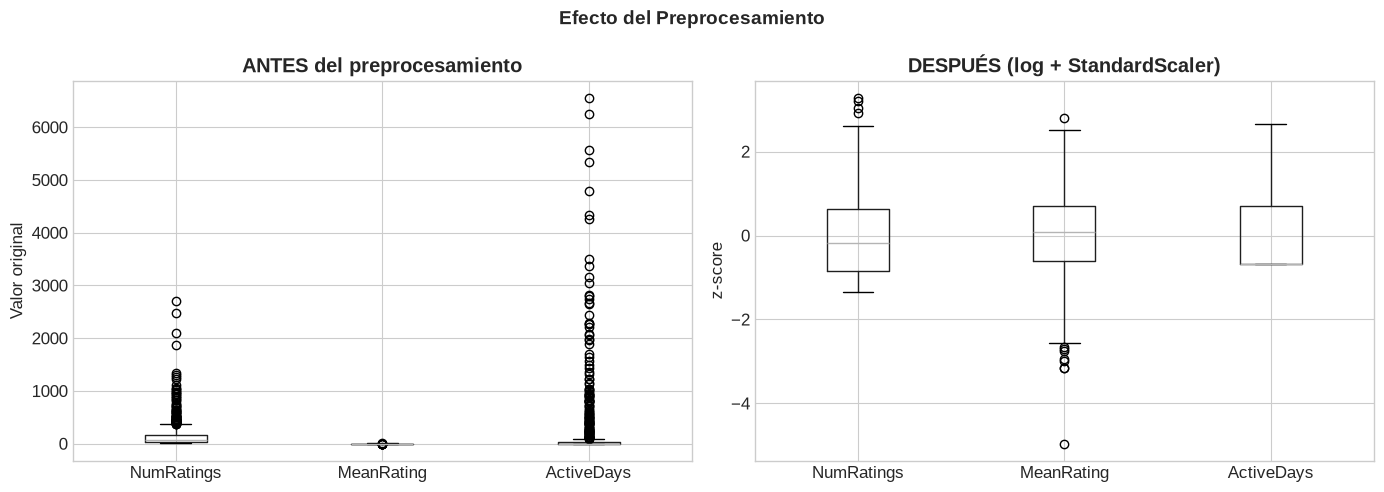

In [14]:
# ── Visualizar el efecto del preprocesamiento ────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df_cluster[cols_demo].boxplot(ax=axes[0])                    # escalas originales muy distintas
axes[0].set_title('ANTES del preprocesamiento', fontweight='bold')
axes[0].set_ylabel('Valor original')

X_scaled_df[cols_demo].boxplot(ax=axes[1])                   # escalas comparables
axes[1].set_title('DESPUÉS (log + StandardScaler)', fontweight='bold')
axes[1].set_ylabel('z-score')

plt.suptitle('Efecto del Preprocesamiento', fontsize=14, fontweight='bold')
save_plot('04_preprocesamiento.png')

---
# Parte 4: Implementación de K-Means

---

## Selección del número de clusters

### Método del codo
Se evalúan valores de K entre 2 y 10, se calcula el WCSS (`inertia_`) para cada uno y se identifica el punto a partir del cual añadir un cluster adicional deja de reducir el WCSS de forma apreciable.

### Coeficiente de silueta
Toma valores entre -1 y 1. Los valores cercanos a 1 indican que los usuarios están próximos a su propio cluster y alejados de los demás.

El coeficiente de silueta tiende a favorecer valores pequeños de K; con K = 2 suele separarse únicamente a los usuarios muy activos de los poco activos. Por ello, la elección se complementa con el método del codo y con la interpretabilidad de los grupos resultantes.

In [15]:
# ── Método del Codo y Silhouette para K = 2 a 10 ─────────────
print("Calculando WCSS y Silhouette para K = 2 a 10...")

k_range = range(2, 11)            # valores de K a evaluar
wcss = []                         # WCSS de cada K
silhouette_scores = []            # Silhouette de cada K

for k in k_range:
    kmeans_temp = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)  # 10 inicios, se queda el mejor
    labels = kmeans_temp.fit_predict(X_scaled)                                # entrenar y asignar
    wcss.append(kmeans_temp.inertia_)                                         # inertia_ = WCSS
    silhouette_scores.append(silhouette_score(X_scaled, labels))              # calidad de la partición

# Reducción porcentual del WCSS al pasar de K-1 a K (ayuda a ubicar el codo)
reduccion = [np.nan] + [(wcss[i - 1] - wcss[i]) / wcss[i - 1] * 100 for i in range(1, len(wcss))]

tabla_k = pd.DataFrame({'K': list(k_range), 'WCSS': wcss,
                        'Reducción WCSS (%)': reduccion,
                        'Silhouette': silhouette_scores}).round(3)
tabla_k.to_csv(OUTPUT_DIR / 'seleccion_k.csv', index=False)   # guardar la tabla
tabla_k

Calculando WCSS y Silhouette para K = 2 a 10...


,K,WCSS,Reducción WCSS (%),Silhouette
0,2,3858.823,NaN,0.229
1,3,3313.512,14.132,0.200
2,4,2911.480,12.133,0.210
3,5,2600.624,10.677,0.192
4,6,2376.013,8.637,0.180
5,7,2224.403,6.381,0.184
6,8,2084.971,6.268,0.180
7,9,1985.193,4.786,0.181
8,10,1918.552,3.357,0.173


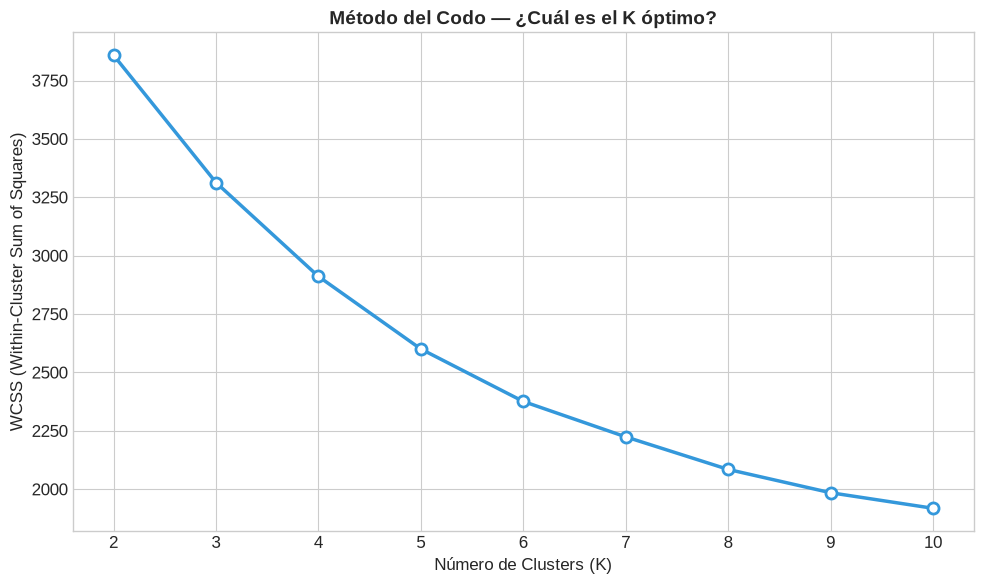

In [16]:
# ── Gráfico del Codo ─────────────────────────────────────────
plt.figure(figsize=(10, 6))
plt.plot(list(k_range), wcss, marker='o', linewidth=2.5, color='#3498db',
         markersize=8, markerfacecolor='white', markeredgewidth=2)
plt.title('Método del Codo — ¿Cuál es el K óptimo?', fontsize=14, fontweight='bold')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('WCSS (Within-Cluster Sum of Squares)')
plt.xticks(list(k_range))
save_plot('05_codo.png')

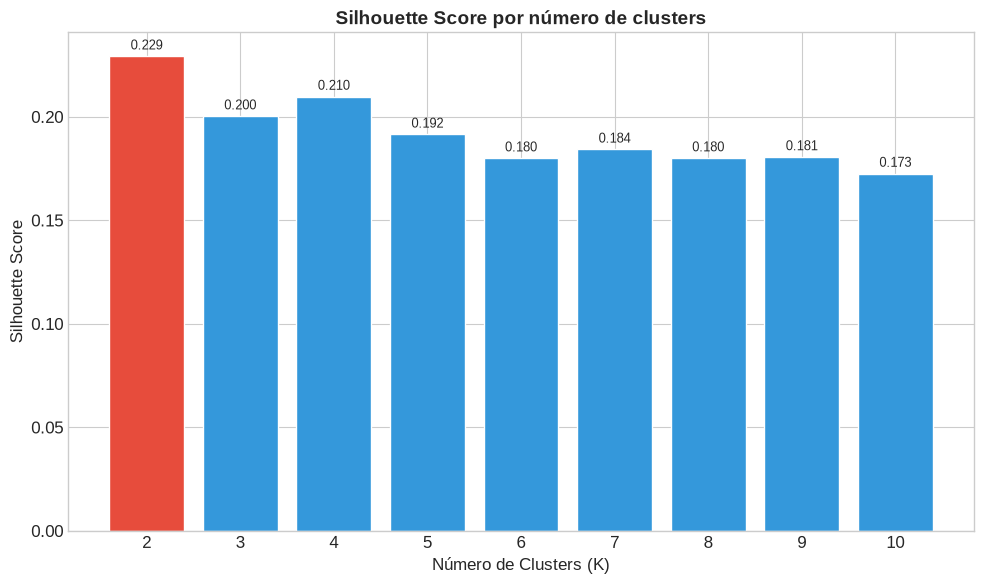

Según Silhouette Score, el mejor K es: 2


In [17]:
# ── Gráfico de Silhouette Score ───────────────────────────────
mejor_k_sil = list(k_range)[int(np.argmax(silhouette_scores))]      # K con mayor Silhouette

plt.figure(figsize=(10, 6))
bars = plt.bar(list(k_range), silhouette_scores,
               color=['#e74c3c' if k == mejor_k_sil else '#3498db' for k in k_range],
               edgecolor='white')
for bar_rect, score in zip(bars, silhouette_scores):                 # anotar cada barra
    plt.text(bar_rect.get_x() + bar_rect.get_width() / 2, bar_rect.get_height() + 0.002,
             f'{score:.3f}', ha='center', va='bottom', fontsize=9)
plt.title('Silhouette Score por número de clusters', fontsize=14, fontweight='bold')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(list(k_range))
save_plot('06_silhouette.png')

print(f"Según Silhouette Score, el mejor K es: {mejor_k_sil}")

---
## Entrenamiento del modelo

El valor de `K_OPTIMO` se fija a partir de la tabla de selección de K; su justificación se presenta en la Parte 5.

- `n_clusters=K_OPTIMO`: número de grupos de usuarios.
- `random_state=777`: semilla para garantizar la reproducibilidad.
- `n_init=10`: número de inicializaciones; se conserva la solución con menor WCSS.

In [18]:
# ── Entrenar el modelo K-Means ────────────────────────────────
K_OPTIMO = 4                                       # ver justificación en la interpretación de la Parte 5

kmeans = KMeans(n_clusters=K_OPTIMO, random_state=RANDOM_STATE, n_init=10)
df_cluster['Cluster'] = kmeans.fit_predict(X_scaled)      # asignar un cluster a cada usuario

print(f"Modelo K-Means entrenado con K = {K_OPTIMO}")
print(f"   WCSS final: {kmeans.inertia_:,.2f}")
print()
print("Distribución de usuarios por cluster:")
conteo = df_cluster['Cluster'].value_counts().sort_index()   # usuarios por cluster
for cluster, count in conteo.items():
    pct = count / len(df_cluster) * 100
    print(f"   Cluster {cluster}: {count:4d} usuarios ({pct:.1f}%) {'█' * int(pct / 2)}")

df_cluster.to_csv(OUTPUT_DIR / 'usuarios_clusters.csv', index=False)   # guardar asignaciones

Modelo K-Means entrenado con K = 4
   WCSS final: 2,911.48

Distribución de usuarios por cluster:
   Cluster 0:  286 usuarios (46.9%) ███████████████████████
   Cluster 1:  151 usuarios (24.8%) ████████████
   Cluster 2:  156 usuarios (25.6%) ████████████
   Cluster 3:   17 usuarios (2.8%) █


---
## Visualización de los clusters

Con ocho variables no es posible representar el espacio completo. Se presentan dos vistas: los clusters sobre dos variables originales y una proyección mediante análisis de componentes principales (PCA) a dos dimensiones. La proyección se emplea solo con fines de visualización; el agrupamiento se realizó con las ocho variables.

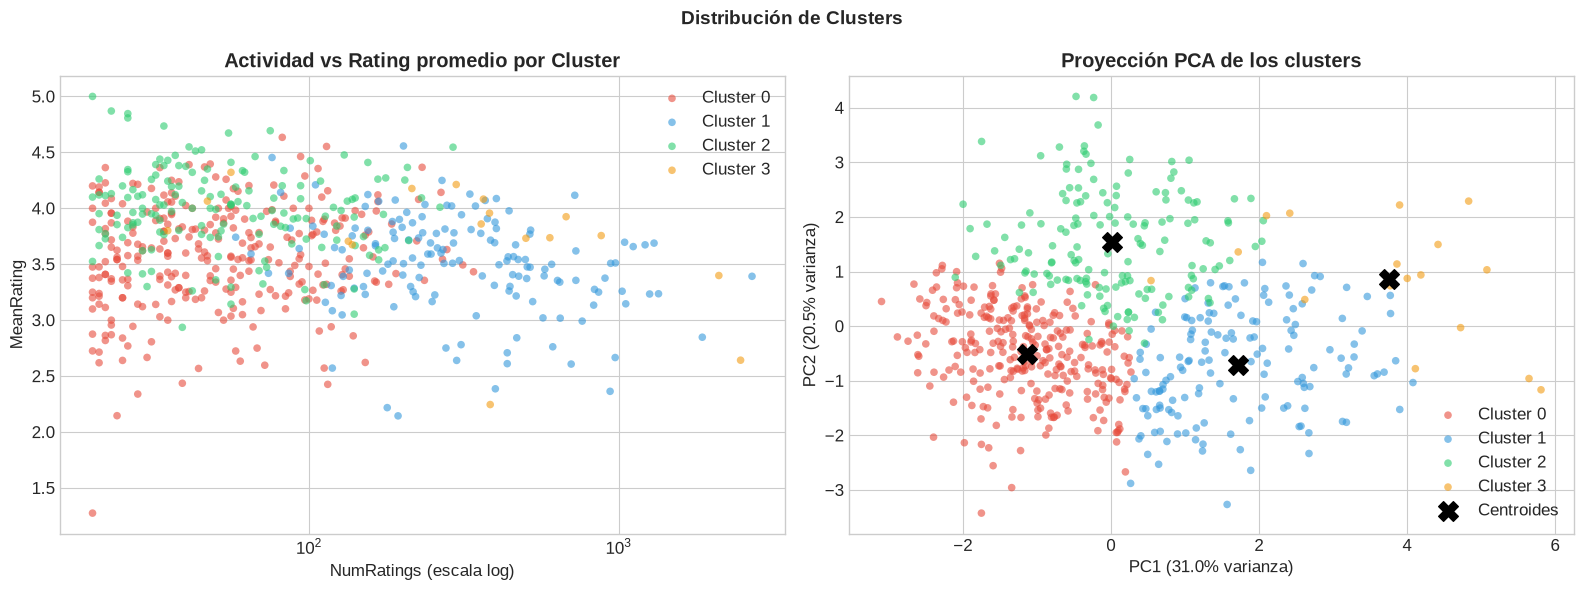

Las 2 componentes PCA conservan 51.6% de la varianza: la superposición visual es parcial.


In [19]:
COLORES = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12', '#9b59b6', '#1abc9c',
           '#34495e', '#e67e22', '#7f8c8d', '#c0392b']        # alcanza para K hasta 10

pca = PCA(n_components=2, random_state=RANDOM_STATE)         # proyección 2D
coords = pca.fit_transform(X_scaled)                         # componentes principales
var_exp = pca.explained_variance_ratio_ * 100                # % de varianza que conserva cada eje

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for cluster_id in range(K_OPTIMO):
    mask = (df_cluster['Cluster'] == cluster_id).values      # usuarios de este cluster
    axes[0].scatter(df_cluster.loc[mask, 'NumRatings'], df_cluster.loc[mask, 'MeanRating'],
                    c=COLORES[cluster_id], label=f'Cluster {cluster_id}', alpha=0.6, s=30, edgecolors='none')
    axes[1].scatter(coords[mask, 0], coords[mask, 1],
                    c=COLORES[cluster_id], label=f'Cluster {cluster_id}', alpha=0.6, s=30, edgecolors='none')

centros_pca = pca.transform(kmeans.cluster_centers_)         # centroides proyectados
axes[1].scatter(centros_pca[:, 0], centros_pca[:, 1], c='black', marker='X', s=200, label='Centroides')

axes[0].set_xscale('log')
axes[0].set_title('Actividad vs Rating promedio por Cluster', fontweight='bold')
axes[0].set_xlabel('NumRatings (escala log)')
axes[0].set_ylabel('MeanRating')
axes[0].legend()
axes[1].set_title('Proyección PCA de los clusters', fontweight='bold')
axes[1].set_xlabel(f'PC1 ({var_exp[0]:.1f}% varianza)')
axes[1].set_ylabel(f'PC2 ({var_exp[1]:.1f}% varianza)')
axes[1].legend()
plt.suptitle('Distribución de Clusters', fontsize=14, fontweight='bold')
save_plot('07_clusters_scatter.png')

print(f"Las 2 componentes PCA conservan {var_exp.sum():.1f}% de la varianza: la superposición visual es parcial.")

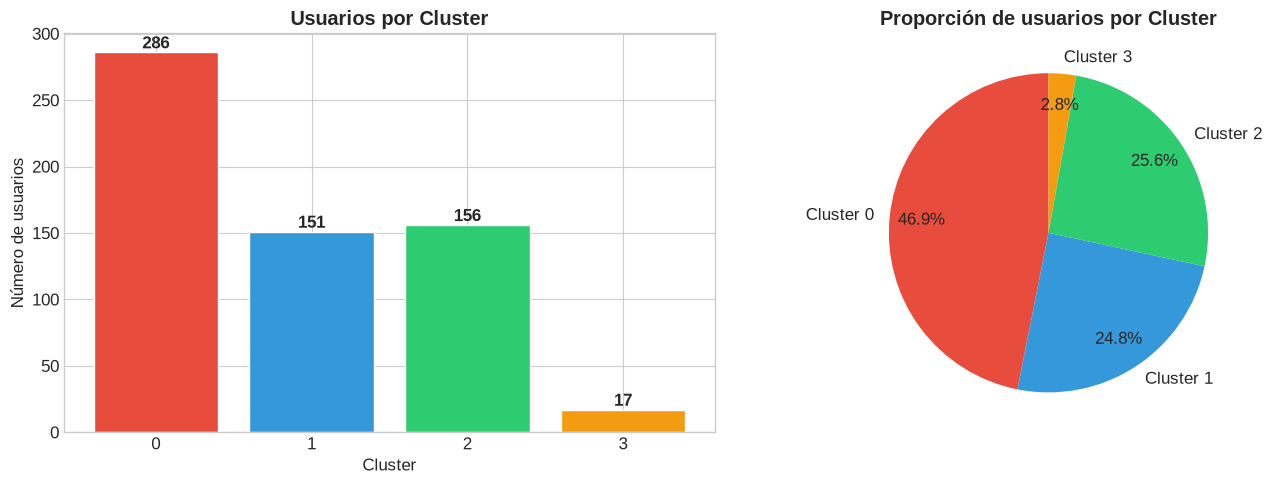

In [20]:
# ── Distribución de usuarios por cluster ──────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colores_k = COLORES[:K_OPTIMO]                               # un color por cluster

axes[0].bar(conteo.index, conteo.values, color=colores_k, edgecolor='white')
axes[0].set_title('Usuarios por Cluster', fontweight='bold')
axes[0].set_xlabel('Cluster')
axes[0].set_ylabel('Número de usuarios')
axes[0].set_xticks(conteo.index)
for idx, val in conteo.items():                              # etiqueta encima de cada barra
    axes[0].text(idx, val + 3, str(val), ha='center', fontweight='bold')

axes[1].pie(conteo.values, labels=[f'Cluster {i}' for i in conteo.index], colors=colores_k,
            autopct='%1.1f%%', startangle=90, pctdistance=0.8)
axes[1].set_title('Proporción de usuarios por Cluster', fontweight='bold')
save_plot('08_tamano_clusters.png')

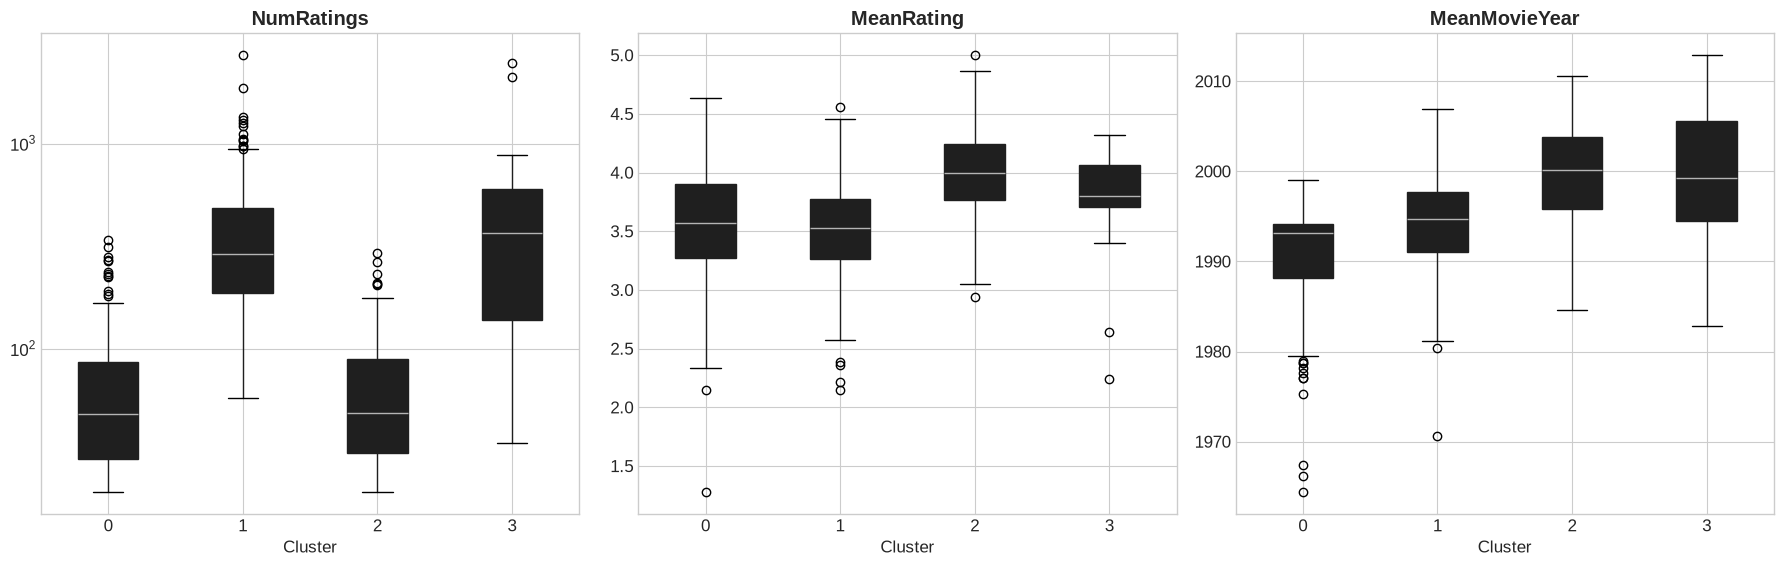

In [21]:
# ── Boxplots de variables clave por cluster ───────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, col in zip(axes, ['NumRatings', 'MeanRating', 'MeanMovieYear']):
    df_cluster.boxplot(column=col, by='Cluster', ax=ax, patch_artist=True)  # una caja por cluster
    ax.set_title(col, fontweight='bold')
    ax.set_xlabel('Cluster')
axes[0].set_yscale('log')                                    # NumRatings en escala log
plt.suptitle('')                                             # quitar el título automático de pandas
save_plot('09_boxplots_clusters.png')

---
## Caracterización de los clusters

Cada cluster se describe mediante los promedios de las variables en su escala original, no estandarizada, para facilitar su interpretación. Para `NumRatings` y `NumTags` se reporta además la mediana, ya que en variables tan asimétricas el promedio está influido por unos pocos usuarios extremos.

In [22]:
# ── Perfil estadístico de cada cluster ───────────────────────
cluster_profile = df_cluster.groupby('Cluster')[features].mean().round(2)          # promedios
cluster_profile['Usuarios'] = conteo                                                # tamaño
cluster_profile['NumRatings_mediana'] = df_cluster.groupby('Cluster')['NumRatings'].median()
cluster_profile['NumTags_mediana'] = df_cluster.groupby('Cluster')['NumTags'].median()
cluster_profile.to_csv(OUTPUT_DIR / 'perfil_clusters.csv')                         # guardar

print("Perfil promedio de cada cluster:")
cluster_profile

Perfil promedio de cada cluster:


,NumRatings,MeanRating,StdRating,NumTags,ActiveDays,RecencyDays,MeanMovieYear,GenreDiversity,Usuarios,NumRatings_mediana,NumTags_mediana
Cluster,,,,,,,,,,,
0,66.10,3.56,1.00,0.03,9.49,6378.51,1990.95,15.65,286,48.0,0.0
1,407.25,3.50,0.94,0.45,780.72,3210.81,1994.38,18.34,151,289.0,0.0
2,69.06,3.99,0.79,0.33,47.86,1469.72,1999.46,15.69,156,49.0,0.0
3,568.35,3.72,0.85,209.00,865.06,1075.53,1999.35,18.12,17,366.0,45.0


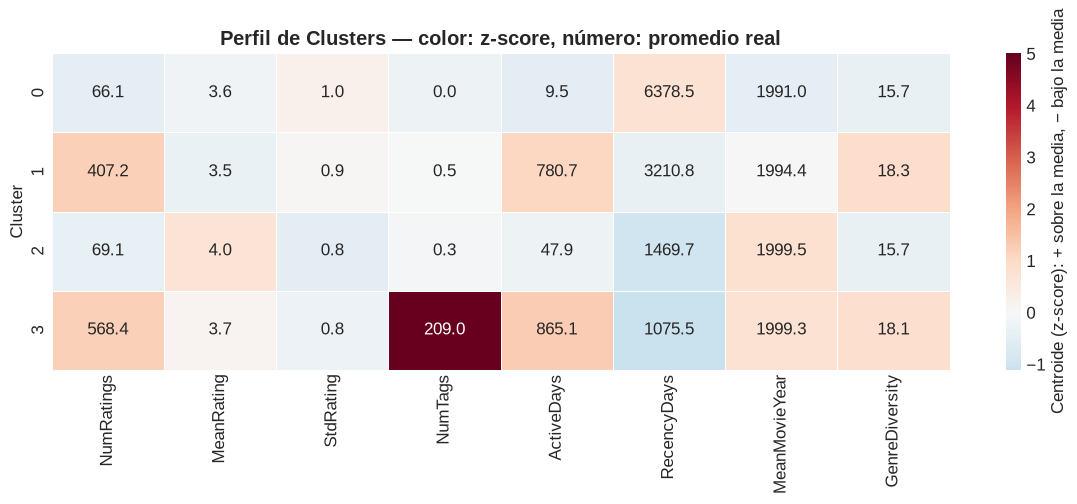

In [23]:
# ── Heatmap de perfil de clusters (centroides en z-score) ─────
centros_z = pd.DataFrame(kmeans.cluster_centers_, columns=features)   # centroides estandarizados
centros_z.index.name = 'Cluster'

plt.figure(figsize=(12, 5))
sns.heatmap(centros_z, annot=cluster_profile[features], fmt='.1f',   # color = z-score, número = valor real
            cmap='RdBu_r', center=0, linewidths=0.5,
            cbar_kws={'label': 'Centroide (z-score): + sobre la media, − bajo la media'})
plt.title('Perfil de Clusters — color: z-score, número: promedio real', fontweight='bold')
save_plot('10_perfil_clusters.png')

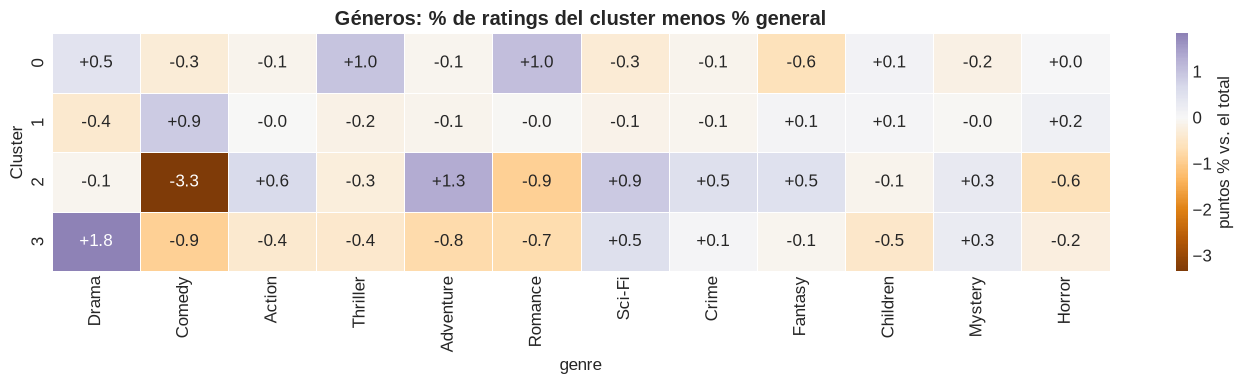

In [24]:
# ── Preferencia de géneros por cluster (variable NO usada en el clustering) ──
g = generos.merge(df_cluster[['userId', 'Cluster']], on='userId')              # género de cada rating + cluster
share = (g.groupby(['Cluster', 'genre']).size()                                 # ratings por cluster y género
           .groupby(level=0).transform(lambda s: s / s.sum() * 100)            # % dentro del cluster
           .unstack(fill_value=0))
general = generos['genre'].value_counts(normalize=True) * 100                   # % en todo el dataset
lift = share[general.index[:12]] - general[general.index[:12]]                   # diferencia vs. el total (12 géneros principales)

plt.figure(figsize=(14, 4))
sns.heatmap(lift, annot=True, fmt='+.1f', cmap='PuOr', center=0, linewidths=0.5,
            cbar_kws={'label': 'puntos % vs. el total'})
plt.title('Géneros: % de ratings del cluster menos % general', fontweight='bold')
save_plot('11_generos_clusters.png')

In [25]:
# ── Interpretación automática de los clusters ─────────────────
# Se describe cada cluster por las variables cuyo centroide se aleja más de la media (|z| ≥ 0.5)
DESCRIP = {
    'NumRatings': ('muy activos', 'poco activos'),
    'MeanRating': ('generosos al calificar', 'exigentes al calificar'),
    'StdRating': ('usan toda la escala', 'calificaciones uniformes'),
    'NumTags': ('escriben etiquetas', 'casi no etiquetan'),
    'ActiveDays': ('historial largo', 'historial corto'),
    'RecencyDays': ('inactivos hace tiempo', 'activos recientemente'),
    'MeanMovieYear': ('prefieren cine reciente', 'prefieren cine clásico'),
    'GenreDiversity': ('gustos variados', 'gustos concentrados'),
}

print("INTERPRETACIÓN DE LOS CLUSTERS")
print("=" * 70)
for cid in range(K_OPTIMO):
    z = centros_z.loc[cid]                                                  # centroide estandarizado
    rasgos = [DESCRIP[c][0] if z[c] > 0 else DESCRIP[c][1]                  # texto según el signo
              for c in z.abs().sort_values(ascending=False).index if abs(z[c]) >= 0.5]
    p = cluster_profile.loc[cid]
    print(f"\n  Cluster {cid} — {int(p['Usuarios'])} usuarios ({p['Usuarios'] / len(df_cluster) * 100:.1f}%)")
    print(f"  Rasgos dominantes : {', '.join(rasgos) or 'cercano al promedio en todo'}")
    print(f"  Ratings (mediana) : {p['NumRatings_mediana']:.0f} | rating promedio: {p['MeanRating']:.2f}"
          f" | año promedio de películas: {p['MeanMovieYear']:.0f} | días sin calificar: {p['RecencyDays']:.0f}")

INTERPRETACIÓN DE LOS CLUSTERS

  Cluster 0 — 286 usuarios (46.9%)
  Rasgos dominantes : inactivos hace tiempo, historial corto
  Ratings (mediana) : 48 | rating promedio: 3.56 | año promedio de películas: 1991 | días sin calificar: 6379

  Cluster 1 — 151 usuarios (24.8%)
  Rasgos dominantes : muy activos, historial largo, gustos variados
  Ratings (mediana) : 289 | rating promedio: 3.50 | año promedio de películas: 1994 | días sin calificar: 3211

  Cluster 2 — 156 usuarios (25.6%)
  Rasgos dominantes : activos recientemente, prefieren cine reciente, generosos al calificar, calificaciones uniformes
  Ratings (mediana) : 49 | rating promedio: 3.99 | año promedio de películas: 1999 | días sin calificar: 1470

  Cluster 3 — 17 usuarios (2.8%)
  Rasgos dominantes : escriben etiquetas, historial largo, muy activos, activos recientemente, gustos variados, prefieren cine reciente
  Ratings (mediana) : 366 | rating promedio: 3.72 | año promedio de películas: 1999 | días sin calificar: 1076


## Denominación de los clusters

**Nota.** La numeración de los clusters (0 a 3) es arbitraria y la asigna el algoritmo. Las denominaciones siguientes corresponden al perfil obtenido con `random_state=777` y deben revisarse si se modifica la semilla o los datos.

| Cluster | Usuarios | Denominación | Descripción |
|---|---:|---|---|
| 0 | 286 (46.9 %) | Usuarios ocasionales inactivos | Mediana de 48 calificaciones, concentradas en su mayoría en una sola sesión (`ActiveDays` promedio de 9.5). Registran en promedio 6,379 días (aproximadamente 17 años) sin calificar y presentan el año de estreno promedio más antiguo (1991). Calificación promedio de 3.56, con la mayor dispersión (1.00). Proporción ligeramente superior de Thriller, Romance y Drama. |
| 1 | 151 (24.8 %) | Usuarios intensivos de larga trayectoria | Mediana de 289 calificaciones, historial extenso (781 días en promedio) y la mayor diversidad de géneros (18.3 de 19). Presentan la calificación promedio más baja (3.50), lo que puede explicarse porque, al calificar un mayor número de películas, también califican más títulos que no son de su agrado. No suelen registrar etiquetas (mediana de 0). |
| 2 | 156 (25.6 %) | Usuarios ocasionales recientes con calificaciones altas | Mediana de 49 calificaciones, con actividad más reciente (1,470 días desde la última). Presentan la calificación promedio más alta (3.99) y la menor dispersión (0.79). Calificaron películas más recientes (año promedio 1999.5), con mayor proporción de Adventure, Sci-Fi y Action, y 3.3 puntos porcentuales menos de Comedy que el total. |
| 3 | 17 (2.8 %) | Usuarios etiquetadores | Grupo reducido de usuarios muy activos (mediana de 366 calificaciones) que además registran etiquetas (mediana de 45; el promedio de 209 está influido por pocos usuarios extremos). Son los usuarios con actividad más reciente (1,076 días) y presentan mayor proporción de Drama (+1.8 puntos porcentuales). |

**Contraste con las hipótesis de la Actividad 1:**
- Se confirman los grupos de usuarios ocasionales, usuarios intensivos y usuarios con calificaciones altas.
- No se identifica un grupo diferenciado de usuarios con calificaciones bajas: el promedio más bajo (3.50, cluster 1) es cercano a la media general.
- La hipótesis de un grupo orientado a películas antiguas no se sostiene por sí sola. El cluster 0 presenta el año de estreno promedio más antiguo, pero es también el que calificó hace más tiempo. `MeanMovieYear` refleja en parte el periodo de actividad del usuario, dado que un usuario activo en el año 2000 no pudo calificar películas posteriores, y no exclusivamente sus preferencias.
- Surge un grupo no previsto, el de los usuarios etiquetadores, que concentra la mayor parte de las 3,683 etiquetas del conjunto.

---

### Aplicación de la segmentación

- **Usuarios intensivos:** recomendación de títulos de nicho y poco populares, dado que ya conocen los títulos más difundidos.
- **Usuarios con calificaciones sistemáticamente altas o bajas:** normalización de las calificaciones por usuario antes de generar recomendaciones, puesto que un 3.5 de un usuario estricto no equivale a un 3.5 de un usuario que califica alto.
- **Usuarios ocasionales o inactivos:** recomendaciones basadas en popularidad y campañas de reactivación.
- **Usuarios nuevos:** asignación al centroide más cercano tras sus primeras calificaciones, como solución al problema de arranque en frío.

---
# Actividad 2: Interpretación de los clusters

Las respuestas se fundamentan en los resultados obtenidos: tabla de selección de K, caracterización de los clusters, mapas de calor y métricas.

---

**1.** ¿Qué cluster representa a los usuarios más valiosos para el sistema de recomendación? ¿Qué variables sustentan esa conclusión?

**Respuesta.** El cluster 1 (usuarios intensivos de larga trayectoria) y, en segundo término, el cluster 3 (usuarios etiquetadores). El cluster 1 presenta una mediana de 289 calificaciones, 781 días de historial y 18.3 géneros distintos; aunque representa el 24.8 % de los usuarios, aporta la mayor parte de las calificaciones que el filtrado colaborativo utiliza para recomendar al resto. El cluster 3, compuesto por 17 usuarios, aporta etiquetas que permiten describir las películas por su contenido. La conclusión se sustenta en `NumRatings`, `ActiveDays`, `GenreDiversity` y `NumTags`. La calificación promedio no se considera un indicador de valor, ya que calificar alto no implica una mayor contribución al sistema.

---

**2.** ¿Qué estrategia se aplicaría a cada cluster?

- **Cluster 0 (ocasionales inactivos):** campaña de reactivación con películas populares y recientes, dado que llevan en promedio cerca de 17 años sin calificar. Mientras dispongan de pocas calificaciones, se recomienda emplear recomendaciones por popularidad en lugar de filtrado colaborativo.
- **Cluster 1 (intensivos de larga trayectoria):** recomendación de títulos de nicho y poco vistos, y fomento del registro de etiquetas, aprovechando la amplitud de géneros que consumen.
- **Cluster 2 (ocasionales recientes con calificaciones altas):** recomendación de estrenos de Adventure, Sci-Fi y Action, e incentivos para que registren más calificaciones y superen la etapa de arranque en frío. Dado que califican alto y con poca variación, conviene normalizar sus calificaciones (restando su promedio) antes de incorporarlas al sistema de recomendación.
- **Cluster 3 (etiquetadores):** aprovechamiento de sus etiquetas para la recomendación basada en contenido y habilitación de funciones de comunidad, como listas o reseñas. Al tratarse de solo 17 usuarios, debe controlarse que sus etiquetas no dominen el sistema.

---

**3.** De acuerdo con el coeficiente de silueta y el método del codo, ¿se modificaría el número de clusters? ¿Por qué?

**Respuesta.** Se mantiene K = 4, con reservas. El coeficiente de silueta alcanza su máximo en K = 2 (0.229), pero esa partición separa básicamente a los usuarios con muchas calificaciones de los que tienen pocas, lo que resulta de poca utilidad para la personalización. K = 4 (0.210) constituye un máximo local: supera a K = 3 (0.200) y a todos los valores K ≥ 5 (≤ 0.192). El método del codo no muestra un punto de inflexión nítido: el WCSS se reduce en 14.1 %, 12.1 % y 10.7 % al pasar a K = 3, 4 y 5, y a partir de K = 6 las reducciones son inferiores al 9 %. Con K = 4 los grupos presentan perfiles diferenciables e interpretables. No se aumenta K porque el cluster 3 ya es muy reducido (17 usuarios) y un número mayor de clusters lo fragmentaría.

---

**4.** ¿Qué otras variables se incorporarían para mejorar la segmentación?

**Respuesta.** Se proponen tres: (a) la proporción de calificaciones por género, que según el mapa de calor de géneros diferencia a los clusters y podría incorporarse directamente al modelo; (b) la popularidad promedio de las películas calificadas por cada usuario, para distinguir el consumo de títulos masivos del de títulos de nicho; y (c) la desviación media respecto al promedio de cada película, que indica si el usuario califica por encima o por debajo del resto. El conjunto `ml-latest-small` no contiene variables demográficas, por lo que no es posible incorporar edad o país.

---

**5.** Si fuera necesario reducir los clusters a dos grupos, ¿cómo se combinarían?

**Respuesta.** Según el nivel de actividad: los clusters 1 y 3 conformarían el grupo de usuarios con historial (medianas de 289 y 366 calificaciones), y los clusters 0 y 2 el de usuarios ocasionales (medianas de 48 y 49). Esta división es la más relevante para un sistema de recomendación: con historial suficiente es posible personalizar mediante filtrado colaborativo; sin él, se recurre a la popularidad. La división es además coherente con el máximo del coeficiente de silueta en K = 2.

---
# Parte 5: Evaluación del modelo

En el aprendizaje no supervisado no existe una respuesta correcta contra la cual comparar. Las métricas empleadas evalúan la calidad interna del agrupamiento:

| Métrica | Qué mide | Criterio |
|---|---|---|
| WCSS (inercia) | Compactación de los clusters | Menor es mejor, aunque disminuye siempre al aumentar K |
| Coeficiente de silueta | Cohesión interna frente a separación entre clusters | Más cercano a 1 es mejor |
| Índice de Davies-Bouldin | Similitud promedio de cada cluster con el más parecido | Menor es mejor |
| Índice de Calinski-Harabasz | Razón entre la dispersión entre clusters y dentro de ellos | Mayor es mejor |

In [26]:
# ── Evaluación del modelo final ───────────────────────────────
labels_final = kmeans.labels_                                 # clusters asignados
silhouette_final = silhouette_score(X_scaled, labels_final)
db_final = davies_bouldin_score(X_scaled, labels_final)
ch_final = calinski_harabasz_score(X_scaled, labels_final)

print(f"MÉTRICAS DEL MODELO K-MEANS (K={K_OPTIMO})")
print("=" * 45)
print(f"  Número de clusters    : {K_OPTIMO}")
print(f"  WCSS (Inercia)        : {kmeans.inertia_:,.2f}")
print(f"  Silhouette Score      : {silhouette_final:.4f}")
print(f"  Davies-Bouldin        : {db_final:.4f}")
print(f"  Calinski-Harabasz     : {ch_final:,.2f}")
print(f"  Iteraciones usadas    : {kmeans.n_iter_}")
print()

if silhouette_final > 0.7:                                    # umbrales usados en clase
    interpretacion = "Excelente — Clusters muy bien definidos"
elif silhouette_final > 0.5:
    interpretacion = "Bueno — Clusters razonablemente bien definidos"
elif silhouette_final > 0.25:
    interpretacion = "Aceptable — Hay superposición entre clusters"
else:
    interpretacion = "Débil — Los clusters se solapan mucho"
print(f"  Interpretación        : {interpretacion}")

pd.DataFrame([{'K': K_OPTIMO, 'WCSS': kmeans.inertia_, 'Silhouette': silhouette_final,
               'Davies_Bouldin': db_final, 'Calinski_Harabasz': ch_final}]
             ).to_csv(OUTPUT_DIR / 'metricas_kmeans.csv', index=False)   # guardar métricas

MÉTRICAS DEL MODELO K-MEANS (K=4)
  Número de clusters    : 4
  WCSS (Inercia)        : 2,911.48
  Silhouette Score      : 0.2098
  Davies-Bouldin        : 1.4187
  Calinski-Harabasz     : 136.58
  Iteraciones usadas    : 14

  Interpretación        : Débil — Los clusters se solapan mucho


In [27]:
# ── Estabilidad: ¿cambian los clusters con otra semilla? ─────
from sklearn.metrics import adjusted_rand_score               # 1 = particiones idénticas

ari = [adjusted_rand_score(labels_final,
                           KMeans(n_clusters=K_OPTIMO, random_state=s, n_init=10).fit_predict(X_scaled))
       for s in [1, 42, 123, 2024, 9999]]                     # 5 semillas distintas
print("ARI vs. el modelo final con 5 semillas:", np.round(ari, 3))
print(f"ARI promedio: {np.mean(ari):.3f}  | semillas con ARI ≥ 0.95: {sum(a >= 0.95 for a in ari)} de {len(ari)}")
print("ARI ≈ 1 → misma partición; ARI bajo → la inicialización llevó a otra solución")

ARI vs. el modelo final con 5 semillas: [1.    0.986 0.99  0.424 0.99 ]
ARI promedio: 0.878  | semillas con ARI ≥ 0.95: 4 de 5
ARI ≈ 1 → misma partición; ARI bajo → la inicialización llevó a otra solución


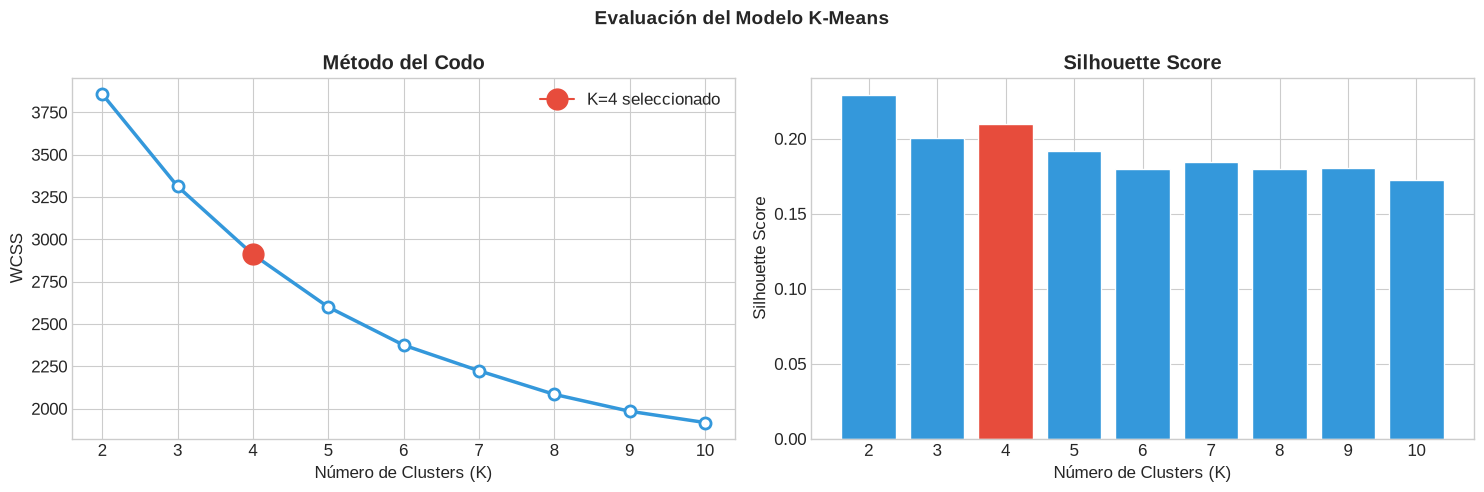

In [28]:
# ── Visualización final: los dos gráficos de evaluación ──────
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
idx_k = list(k_range).index(K_OPTIMO)                         # posición de K_OPTIMO en las listas

axes[0].plot(list(k_range), wcss, marker='o', linewidth=2.5, color='#3498db',
             markersize=8, markerfacecolor='white', markeredgewidth=2)
axes[0].plot(K_OPTIMO, wcss[idx_k], marker='o', markersize=15, color='#e74c3c',
             zorder=5, label=f'K={K_OPTIMO} seleccionado')
axes[0].set_title('Método del Codo', fontweight='bold')
axes[0].set_xlabel('Número de Clusters (K)')
axes[0].set_ylabel('WCSS')
axes[0].set_xticks(list(k_range))
axes[0].legend()

axes[1].bar(list(k_range), silhouette_scores,
            color=['#e74c3c' if k == K_OPTIMO else '#3498db' for k in k_range], edgecolor='white')
axes[1].set_title('Silhouette Score', fontweight='bold')
axes[1].set_xlabel('Número de Clusters (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_xticks(list(k_range))

plt.suptitle('Evaluación del Modelo K-Means', fontsize=14, fontweight='bold')
save_plot('12_evaluacion.png')

### Interpretación de la evaluación

- **Elección de K.** El método del codo no presenta un punto de inflexión nítido; las reducciones del WCSS disminuyen de forma gradual (14.1 %, 12.1 %, 10.7 %, 8.6 %). El coeficiente de silueta es máximo en K = 2 (0.229) y presenta un máximo local en K = 4 (0.210). Se selecciona K = 4 por producir segmentos interpretables y útiles (véase la respuesta 3 de la Actividad 2).
- **Calidad.** El coeficiente de silueta de 0.210 corresponde, según los umbrales empleados en clase, a una estructura débil, con superposición considerable entre clusters, tal como se observa en la proyección PCA. Los índices de Davies-Bouldin (1.42) y Calinski-Harabasz (136.6) carecen de un umbral absoluto y resultan útiles principalmente para comparar distintos valores de K. Este resultado es esperable, dado que el comportamiento de los usuarios constituye un continuo y no grupos naturalmente separados; en este caso K-Means segmenta dicho continuo más que descubrir grupos nítidos.
- **Estabilidad.** Con cuatro de las cinco semillas evaluadas, el índice de Rand ajustado (ARI) fue igual o superior a 0.986, lo que indica particiones prácticamente idénticas; con una semilla descendió a 0.424 (ARI promedio de 0.878). Existe, por lo tanto, al menos una solución alternativa con K = 4. El parámetro `n_init=10` conserva la solución de menor WCSS, que coincide con la obtenida en la mayoría de las semillas.
- **Limitación.** Las métricas internas no permiten determinar si la segmentación es útil. Esa valoración depende de la interpretabilidad de los perfiles y, en un sistema real, de verificar si la recomendación por segmento mejora los resultados.

---
# Conclusiones

---

## Síntesis del trabajo

1. **Cambio de unidad de análisis:** de la calificación individual (aprendizaje supervisado, hito 3) al usuario (aprendizaje no supervisado, hito 4).
2. **Ingeniería de variables:** construcción de un perfil por usuario a partir de 100,836 calificaciones.
3. **Preprocesamiento:** transformación logarítmica de las variables asimétricas y estandarización.
4. **Selección de K:** método del codo, coeficiente de silueta e interpretabilidad de los grupos.
5. **Caracterización:** descripción de los clusters mediante promedios en escala original, centroides estandarizados y preferencias de género.
6. **Evaluación:** coeficiente de silueta, índices de Davies-Bouldin y Calinski-Harabasz, y análisis de estabilidad mediante ARI.

---

## Relación con los hitos anteriores

- En el hito 3, `user_mean_rating` y `user_rating_count` fueron variables determinantes para predecir si una calificación es alta. El agrupamiento confirma que los usuarios difieren de forma sistemática en esas dimensiones.
- La pertenencia a un cluster podría incorporarse como variable al modelo supervisado del hito 3 para evaluar si mejora la predicción. En ese caso, los clusters deberían calcularse únicamente con los datos de entrenamiento para evitar fuga de información.

---

## Limitaciones

| Limitación | Implicación en el proyecto |
|---|---|
| Definición previa de K | K se eligió combinando métricas y criterio de aplicación; otros valores son defendibles |
| Sensibilidad a valores atípicos | Atenuada mediante la transformación logarítmica, aunque los usuarios con miles de calificaciones mantienen influencia |
| Supuesto de clusters esféricos | El comportamiento de los usuarios es un continuo y los límites entre grupos son difusos |
| Variables redundantes | `NumRatings` y `GenreDiversity` presentan una correlación de Spearman de 0.82, por lo que la actividad tiene un peso aproximadamente doble en la distancia |
| Efecto temporal | `MeanMovieYear` y `RecencyDays` dependen del periodo en que el usuario estuvo activo (1996–2018) |
| Ausencia de datos demográficos | La segmentación se basa únicamente en el comportamiento |
| Conjunto de desarrollo | `ml-latest-small` (610 usuarios) no es representativo de la totalidad de la plataforma |
| Ausencia de causalidad | Los clusters describen asociaciones y no explican las causas del comportamiento de los usuarios |

---

## Trabajo futuro

| Algoritmo | Aporte al proyecto |
|---|---|
| DBSCAN | Identificación de usuarios atípicos (por ejemplo, con miles de calificaciones) como ruido |
| Clustering jerárquico | Análisis de la fusión de segmentos mediante un dendrograma, sin fijar K |
| Modelos de mezcla gaussiana | Asignación probabilística, que permite a un usuario pertenecer parcialmente a varios segmentos |
| PCA previo a K-Means | Reducción de la redundancia entre variables correlacionadas antes del agrupamiento |

In [29]:
# ── Resumen final ejecutable ──────────────────────────────────
print("RESUMEN — K-Means Clustering sobre MovieLens")
print("=" * 50)
print(f"  Dataset          : MovieLens ml-latest-small")
print(f"  Registros        : {len(df_cluster):,} usuarios ({len(ratings):,} ratings)")
print(f"  Features usados  : {len(features)}")
print(f"  Algoritmo        : K-Means (scikit-learn)")
print(f"  K seleccionado   : {K_OPTIMO} clusters")
print(f"  WCSS             : {kmeans.inertia_:,.2f}")
print(f"  Silhouette Score : {silhouette_final:.4f}")
print()
print("  Distribución de clusters:")
for cid in range(K_OPTIMO):
    p = cluster_profile.loc[cid]
    print(f"    Cluster {cid}: {int(p['Usuarios']):4d} usuarios | "
          f"ratings (mediana) ≈ {p['NumRatings_mediana']:.0f} | rating promedio ≈ {p['MeanRating']:.2f}")
print()
print("  Archivos generados en:", OUTPUT_DIR.resolve())

RESUMEN — K-Means Clustering sobre MovieLens
  Dataset          : MovieLens ml-latest-small
  Registros        : 610 usuarios (100,836 ratings)
  Features usados  : 8
  Algoritmo        : K-Means (scikit-learn)
  K seleccionado   : 4 clusters
  WCSS             : 2,911.48
  Silhouette Score : 0.2098

  Distribución de clusters:
    Cluster 0:  286 usuarios | ratings (mediana) ≈ 48 | rating promedio ≈ 3.56
    Cluster 1:  151 usuarios | ratings (mediana) ≈ 289 | rating promedio ≈ 3.50
    Cluster 2:  156 usuarios | ratings (mediana) ≈ 49 | rating promedio ≈ 3.99
    Cluster 3:   17 usuarios | ratings (mediana) ≈ 366 | rating promedio ≈ 3.72

  Archivos generados en: /home/ruper/Documentos/mineria_datos/output_kmeans


---
## Uso de inteligencia artificial

- **Herramienta:** Claude Code (Anthropic).
- **Finalidad:** adaptación de la estructura del cuaderno de clase `h4_1_kmeans_ifood` al conjunto de datos del proyecto (MovieLens), propuesta de las variables del perfil de usuario, redacción del código comentado y de los textos explicativos.
- **Revisión del grupo:** _____ (indicar qué se revisó, qué se modificó y cómo se verificaron los resultados).

---

## Referencia

Harper, F. M., y Konstan, J. A. (2015). The MovieLens Datasets: History and Context. *ACM Transactions on Interactive Intelligent Systems*, 5(4), 19:1-19:19. https://doi.org/10.1145/2827872